#  Unsupervised Learning 


## Imports and reproducibility

In [ ]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titleweight"] = "bold"   

##  Load the prepared feature splits


In [36]:
def find_data_dir():
    candidates = [
        Path("../data/final"),
        Path("data/final"),
        Path("."),
        Path("/mnt/data"),
    ]
    required = ["X_train.csv", "X_val.csv", "X_test.csv"]
    for folder in candidates:
        if all((folder / name).exists() for name in required):
            return folder
    raise FileNotFoundError(
        "Could not find X_train.csv, X_val.csv, and X_test.csv. "
        "Place them in ../data/final or in the same folder as this notebook."
    )

DATA_DIR = find_data_dir()
print("Using data directory:", DATA_DIR.resolve())

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_val   = pd.read_csv(DATA_DIR / "X_val.csv")
X_test  = pd.read_csv(DATA_DIR / "X_test.csv")

# Keep the original split label for traceability; it is not a clustering feature.
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

X_train["data_split"] = "train"
X_val["data_split"] = "validation"
X_test["data_split"] = "test"

X_all = pd.concat([X_train, X_val, X_test], ignore_index=True)

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)
print("Combined shape:", X_all.shape)
display(X_all.head())

Using data directory: D:\ai uni\Level 3\semster 1\projects\data analysis\Air Quality Forecasting - main\Air Quality Forecasting\data\final
Train shape: (44847, 26)
Validation shape: (12010, 26)
Test shape: (11134, 26)
Combined shape: (67991, 26)


,O3_AQI_lag1,O3_AQI_lag7,O3_AQI_lag30,O3_roll_mean7,O3_roll_std7,NO2_AQI_lag1,NO2_AQI_lag7,NO2_AQI_lag30,NO2_roll_mean7,NO2_roll_std7,...,CO_AQI_lag7,CO_AQI_lag30,CO_roll_mean7,CO_roll_std7,Year,Month,Region_le,area_type_le,Season_le,data_split
0,-0.531698,-0.411098,-0.648010,-0.718466,-0.577324,-0.197041,0.562659,0.404530,0.398656,-0.276421,...,2.885844,2.350018,3.517918,0.709559,-1.543396,1,2.0,1.0,3.0,train
1,-0.413831,-0.411098,-0.351991,-0.718466,-0.577324,1.773133,-0.194908,-1.030626,0.619200,0.541532,...,2.369617,1.066093,3.606690,0.760251,-1.543396,2,2.0,1.0,3.0,train
2,-0.531698,-0.941445,-0.351991,-0.739611,-0.596927,2.379340,0.259632,-1.030626,1.087858,1.246458,...,2.369617,1.322878,4.050550,1.322623,-1.543396,2,2.0,1.0,3.0,train
3,-1.238902,-0.941445,-0.825621,-0.792475,-0.406864,2.455116,1.092957,-0.124212,1.487596,1.660257,...,3.143957,1.322878,4.671955,2.020650,-1.543396,2,2.0,1.0,3.0,train
4,-1.003167,-0.234316,-0.766418,-0.803048,-0.383557,1.318478,0.789930,-0.124212,1.528948,1.662781,...,4.434524,1.579663,4.139322,3.596102,-1.543396,2,2.0,1.0,3.0,train


## 3. Data inspection

In [37]:
print("Rows and columns:", X_all.shape)
print(" Missing values:")
display(X_all.isna().sum().sort_values(ascending=False).head(10).to_frame("missing_count"))

print("Data types:")
display(X_all.dtypes.value_counts().to_frame("number_of_columns"))

print("Split distribution:")
display(X_all["data_split"].value_counts().to_frame("rows"))

# Confirm that all feature columns are numeric and identify any unexpected values
feature_columns = [c for c in X_all.columns if c != "data_split"]
non_numeric = X_all[feature_columns].select_dtypes(exclude=np.number).columns.tolist()
print("Non-numeric feature columns:", non_numeric)

Rows and columns: (67991, 26)
 Missing values:


,missing_count
O3_AQI_lag1,0
O3_AQI_lag7,0
Season_le,0
area_type_le,0
Region_le,0
Month,0
Year,0
CO_roll_std7,0
CO_roll_mean7,0
CO_AQI_lag30,0


Data types:


,number_of_columns
float64,24
int64,1
object,1


Split distribution:


,rows
data_split,
train,44847
validation,12010
test,11134


Non-numeric feature columns: []


##  Feature selection for pollution-pattern clustering

The prepared features contain 20 pollutant-history variables:
- `O3`, `NO2`, `SO2`, and `CO` AQI lag values (1, 7, and 30 days).
- Seven-day rolling mean and standard deviation for each pollutant.

We exclude the encoded calendar/location context columns from distance calculations. These can still be used later to interpret clusters if metadata is available.

In [38]:
pollutants = ["O3", "NO2", "SO2", "CO"]
pollution_features = []

for pollutant in pollutants:
    pollution_features.extend([
        f"{pollutant}_AQI_lag1",
        f"{pollutant}_AQI_lag7",
        f"{pollutant}_AQI_lag30",
        f"{pollutant}_roll_mean7",
        f"{pollutant}_roll_std7",
    ])

missing_features = [c for c in pollution_features if c not in X_all.columns]
if missing_features:
    raise ValueError(f"Expected pollutant features are missing: {missing_features}")

X_cluster = X_all[pollution_features].copy()

# The supplied preprocessing is expected to have handled missing values.
# Drop incomplete rows only if any are unexpectedly present, while preserving row indices.
valid_mask = X_cluster.notna().all(axis=1)
if not valid_mask.all():
    print(f"Dropping {(~valid_mask).sum():,} rows with missing clustering features.")
    X_cluster = X_cluster.loc[valid_mask].copy()
    X_all = X_all.loc[valid_mask].copy()

print("Selected features:", len(pollution_features))
print("Clustering data shape:", X_cluster.shape)
display(X_cluster.describe().T.round(3))

Selected features: 20
Clustering data shape: (67991, 20)


,count,mean,std,min,25%,50%,75%,max
O3_AQI_lag1,67991.0,0.031,0.988,-2.064,-0.591,-0.119,0.411,9.723
O3_AQI_lag7,67991.0,0.031,0.991,-2.061,-0.588,-0.116,0.414,9.724
O3_AQI_lag30,67991.0,0.028,0.990,-2.069,-0.589,-0.115,0.418,9.772
O3_roll_mean7,67991.0,0.039,0.985,-2.452,-0.655,-0.105,0.550,6.640
O3_roll_std7,67991.0,0.009,0.982,-1.240,-0.598,-0.302,0.198,7.823
NO2_AQI_lag1,67991.0,-0.049,0.993,-1.713,-0.879,-0.121,0.636,6.699
NO2_AQI_lag7,67991.0,-0.046,0.993,-1.710,-0.877,-0.119,0.638,6.699
NO2_AQI_lag30,67991.0,-0.045,0.994,-1.710,-0.880,-0.124,0.631,6.674
NO2_roll_mean7,67991.0,-0.061,0.998,-2.179,-0.801,-0.111,0.619,4.617
NO2_roll_std7,67991.0,-0.035,0.996,-2.016,-0.743,-0.156,0.553,8.786


## Feature distributions

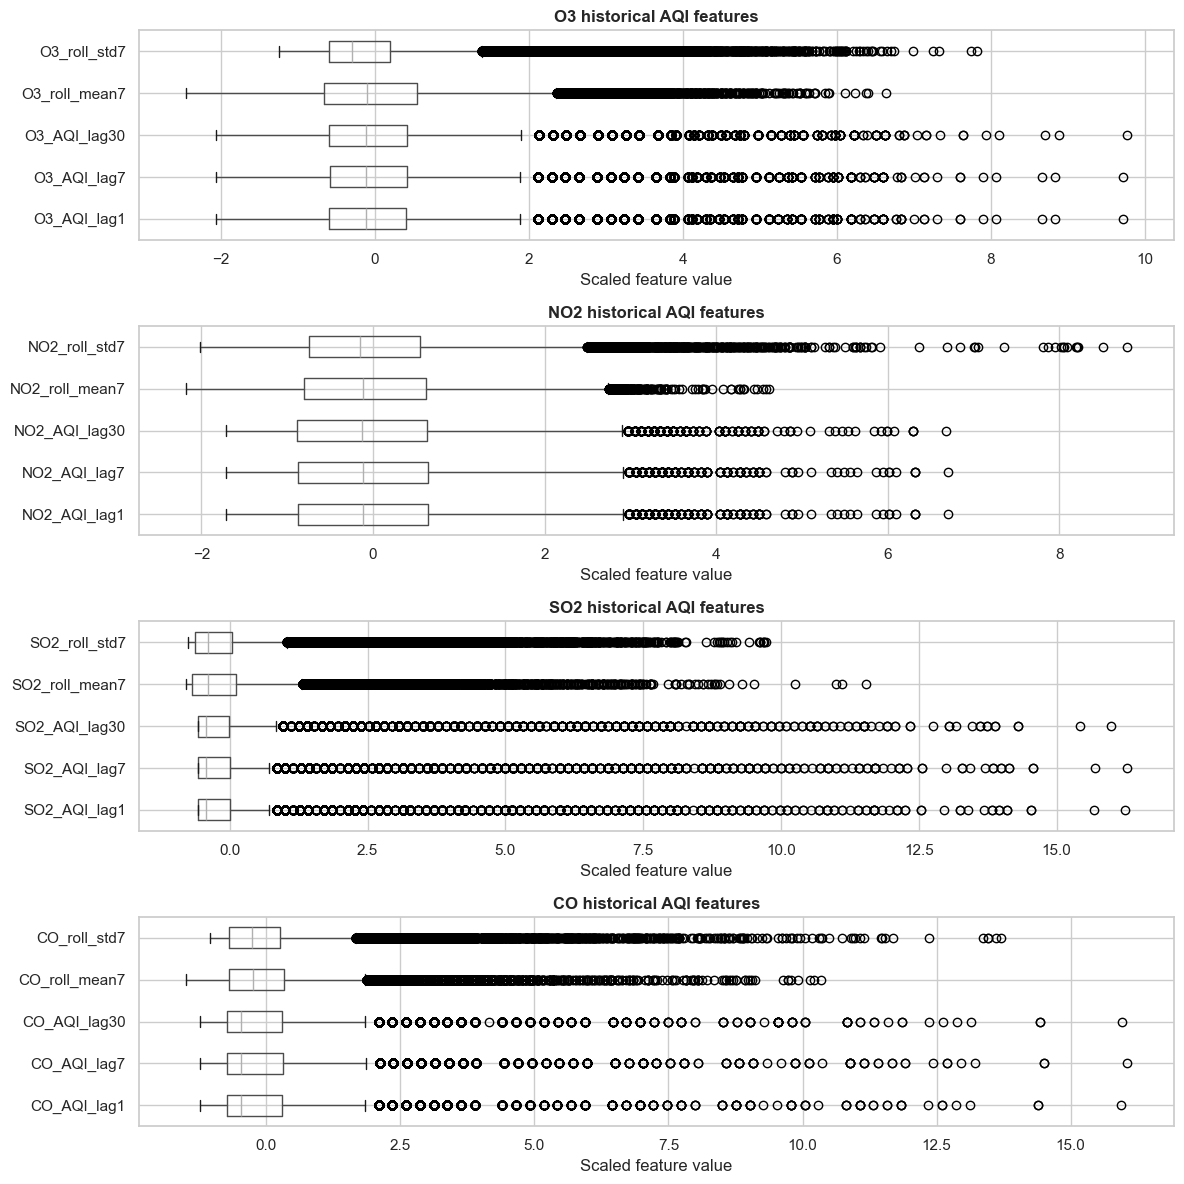

In [39]:
fig, axes = plt.subplots(4, 1, figsize=(12, 12))
for ax, pollutant in zip(axes, pollutants):
    cols = [c for c in pollution_features if c.startswith(pollutant + "_")]
    X_cluster[cols].boxplot(ax=ax, vert=False)
    ax.set_title(f"{pollutant} historical AQI features")
    ax.set_xlabel("Scaled feature value")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

## Choose K — Elbow Method and Silhouette Score

We evaluate candidate values of K on a reproducible sample to keep the analysis efficient. The final KMeans model will then be fitted on **all valid rows**.

- **Inertia / WCSS:** measures within-cluster compactness; look for the point where improvement starts slowing down (the elbow).
- **Silhouette Score:** measures how well-separated the clusters are; higher is better, but interpret it together with the elbow and cluster sizes.

- The selected K is based on the observed results, not a hard-coded assumption.

In [40]:
EVAL_SAMPLE_SIZE = min(10000, len(X_cluster))
X_eval = X_cluster.sample(n=EVAL_SAMPLE_SIZE, random_state=RANDOM_STATE)

k_values = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_eval)
    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_eval, labels, sample_size=min(5000, len(X_eval)),
                         random_state=RANDOM_STATE)
    )

k_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})
display(k_results.round(4))

,K,Inertia,Silhouette Score
0,2,160142.4902,0.2256
1,3,144199.9846,0.2129
2,4,128895.0899,0.1936
3,5,119018.8397,0.1574
4,6,114356.2368,0.1103
5,7,110606.5804,0.1082
6,8,107155.9661,0.1040
7,9,104111.6465,0.1059
8,10,101105.0899,0.0935


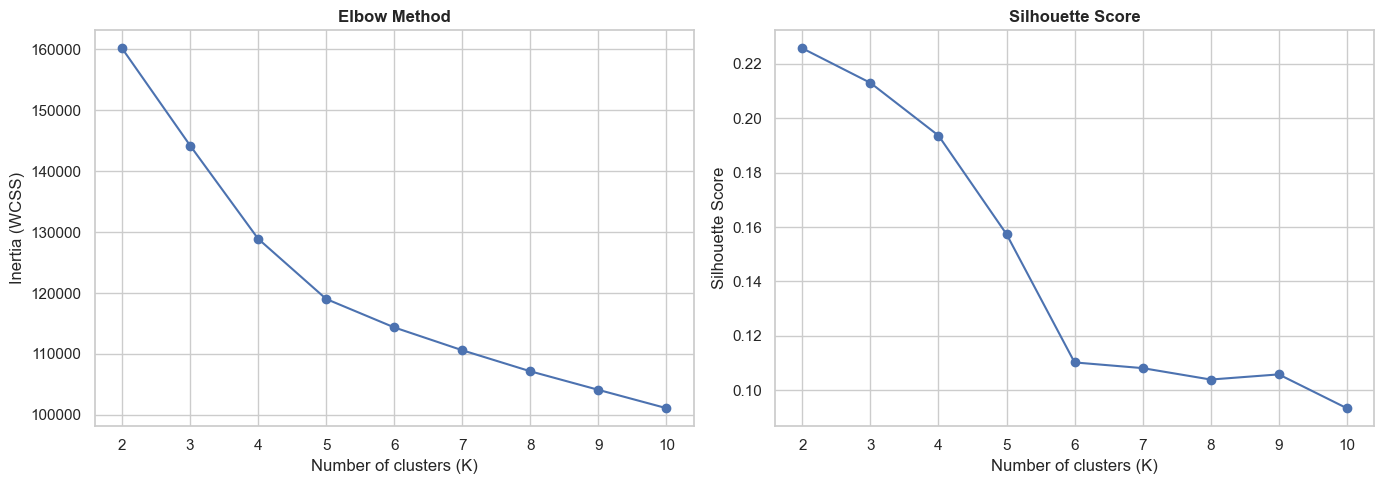

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_results["K"], k_results["Inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_xticks(list(k_values))

axes[1].plot(k_results["K"], k_results["Silhouette Score"], marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))

plt.tight_layout()
plt.show()

### Select the final K

The code below proposes the K with the highest Silhouette Score. Review the Elbow chart and cluster-size distribution as well. If the elbow clearly supports a nearby K and the silhouette scores are very close, choose the simpler and more interpretable solution and update `BEST_K` manually.

In [42]:
BEST_K = int(k_results.loc[k_results["Silhouette Score"].idxmax(), "K"])
print("Initial recommended K from Silhouette Score:", BEST_K)

# If visual inspection of the Elbow/Silhouette charts supports another value,
# change BEST_K here before fitting the final model.
# Example: BEST_K = 4

Initial recommended K from Silhouette Score: 2


### Final KMeans model

In [43]:
kmeans = KMeans(
    n_clusters=BEST_K,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_cluster)

clustered_data = X_all.copy()
clustered_data["KMeans_Cluster"] = kmeans_labels

print("KMeans fitted successfully.")
print("Final K:", BEST_K)
print("Final inertia:", round(kmeans.inertia_, 3))
print("Silhouette score (sample):",
      round(silhouette_score(
          X_cluster,
          kmeans_labels,
          sample_size=min(5000, len(X_cluster)),
          random_state=RANDOM_STATE
      ), 4))

KMeans fitted successfully.
Final K: 2
Final inertia: 1046561.034
Silhouette score (sample): 0.224


### Cluster distribution

,Number of records,Percentage (%)
KMeans_Cluster,,
0,25925,38.13
1,42066,61.87


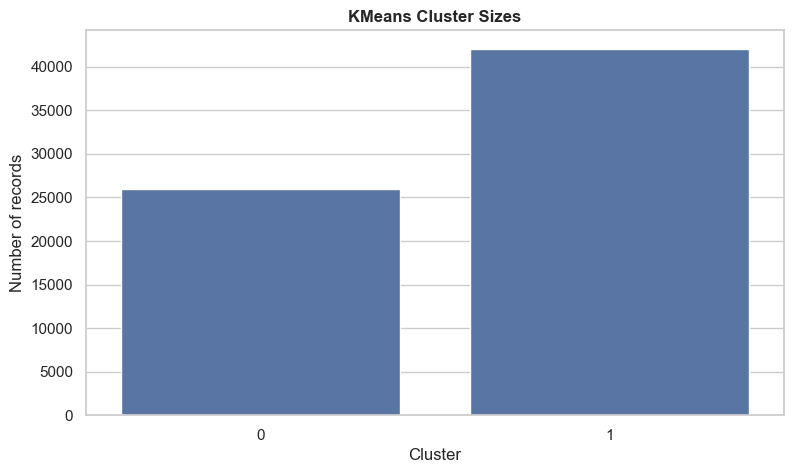

In [44]:
cluster_counts = clustered_data["KMeans_Cluster"].value_counts().sort_index()
cluster_percent = (cluster_counts / len(clustered_data) * 100).round(2)

cluster_distribution = pd.DataFrame({
    "Number of records": cluster_counts,
    "Percentage (%)": cluster_percent
})
display(cluster_distribution)

plt.figure(figsize=(9, 5))
sns.barplot(x=cluster_distribution.index, y=cluster_distribution["Number of records"])
plt.title("KMeans Cluster Sizes")
plt.xlabel("Cluster")
plt.ylabel("Number of records")
plt.show()

### Cluster profiling

We calculate the mean of each pollutant-history feature per cluster. Because the input features are scaled, the profile values are relative:
- Positive values: above the feature's reference mean.
- Negative values: below the feature's reference mean.
- Values near zero: close to the reference mean.

Use the profile to describe clusters as relative pollution-pattern groups. Avoid calling a cluster an absolute AQI health category based only on scaled lag/rolling features.

In [45]:
cluster_profile = clustered_data.groupby("KMeans_Cluster")[pollution_features].mean()
display(cluster_profile.round(3))

,O3_AQI_lag1,O3_AQI_lag7,O3_AQI_lag30,O3_roll_mean7,O3_roll_std7,NO2_AQI_lag1,NO2_AQI_lag7,NO2_AQI_lag30,NO2_roll_mean7,NO2_roll_std7,SO2_AQI_lag1,SO2_AQI_lag7,SO2_AQI_lag30,SO2_roll_mean7,SO2_roll_std7,CO_AQI_lag1,CO_AQI_lag7,CO_AQI_lag30,CO_roll_mean7,CO_roll_std7
KMeans_Cluster,,,,,,,,,,,,,,,,,,,,
0,-0.291,-0.306,-0.324,-0.371,-0.231,0.661,0.663,0.593,0.785,0.407,0.376,0.377,0.339,0.491,0.432,0.570,0.578,0.534,0.663,0.607
1,0.230,0.239,0.245,0.292,0.158,-0.487,-0.483,-0.438,-0.582,-0.308,-0.321,-0.320,-0.297,-0.426,-0.341,-0.424,-0.426,-0.403,-0.494,-0.419


,O3,NO2,SO2,CO
KMeans_Cluster,,,,
0,-0.305,0.622,0.403,0.590
1,0.233,-0.459,-0.341,-0.433


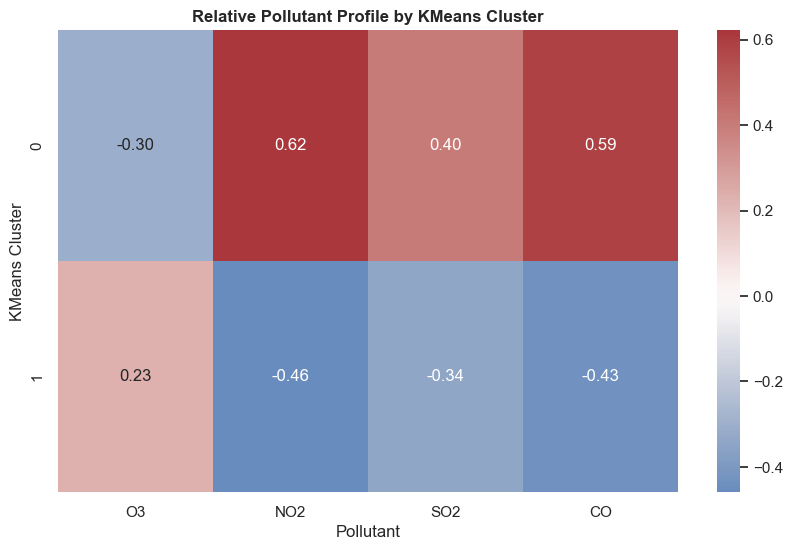

In [46]:
# Average profile across the lag/rolling features for each pollutant.
pollutant_profile = pd.DataFrame(index=cluster_profile.index)

for pollutant in pollutants:
    cols = [c for c in pollution_features if c.startswith(pollutant + "_")]
    pollutant_profile[pollutant] = cluster_profile[cols].mean(axis=1)

display(pollutant_profile.round(3))

plt.figure(figsize=(10, 6))
sns.heatmap(pollutant_profile, annot=True, fmt=".2f", center=0, cmap="vlag")
plt.title("Relative Pollutant Profile by KMeans Cluster")
plt.xlabel("Pollutant")
plt.ylabel("KMeans Cluster")
plt.show()

### Detailed feature profile heatmap

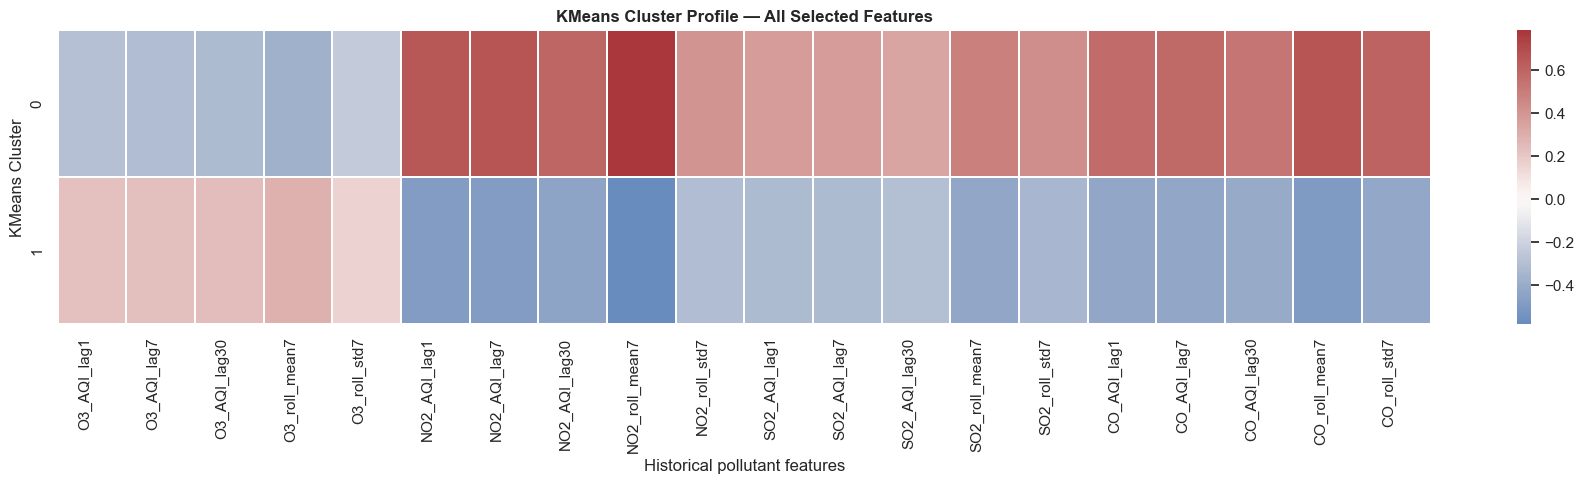

In [47]:
plt.figure(figsize=(18, max(5, BEST_K * 1.1)))
sns.heatmap(cluster_profile, cmap="vlag", center=0, linewidths=0.25)
plt.title("KMeans Cluster Profile — All Selected Features")
plt.xlabel("Historical pollutant features")
plt.ylabel("KMeans Cluster")
plt.xticks(rotation=90, ha="right")
plt.tight_layout()
plt.show()

###  Visualize Pollutant Profiles Across KMeans Clusters

This visualization compares the average historical AQI values of O3, NO2, SO2, and CO across the identified KMeans clusters.


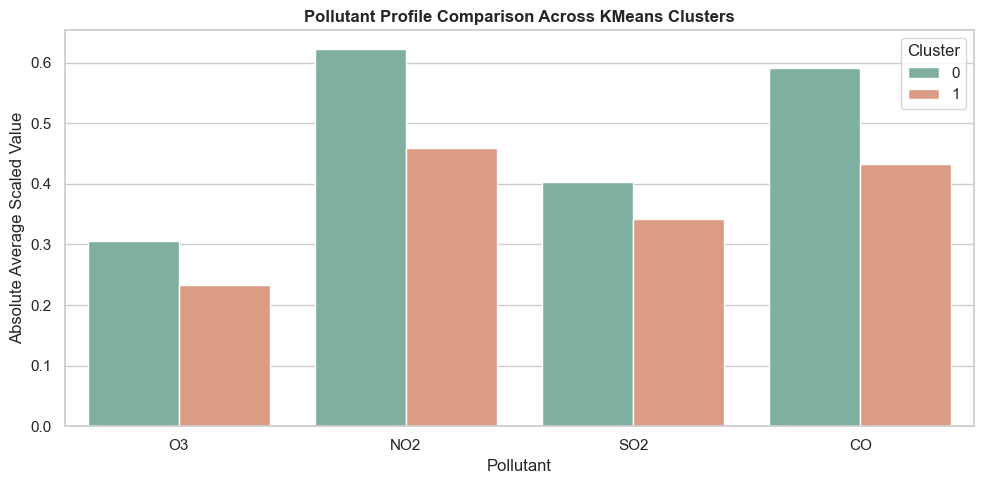

In [50]:
profile_plot = pollutant_profile.copy()

if "KMeans_Cluster" not in profile_plot.columns:
    profile_plot = profile_plot.reset_index()

profile_plot = profile_plot.set_index("KMeans_Cluster")
profile_plot = profile_plot.abs()

profile_plot = (
    profile_plot
    .reset_index()
    .melt(
        id_vars="KMeans_Cluster",
        var_name="Pollutant",
        value_name="Absolute Average Scaled Value"
    )
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=profile_plot,
    x="Pollutant",
    y="Absolute Average Scaled Value",
    hue="KMeans_Cluster",
    palette=["#76B7A5", "#E99578"]
)

plt.title("Pollutant Profile Comparison Across KMeans Clusters")
plt.xlabel("Pollutant")
plt.ylabel("Absolute Average Scaled Value")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

##  DBSCAN — density-based anomaly detection

- DBSCAN groups dense regions and labels isolated observations as noise (`-1`). It is useful for detecting unusual combinations of historical pollutant features.



In [51]:
DBSCAN_SAMPLE_SIZE = min(8000, len(X_cluster))
dbscan_indices = X_cluster.sample(
    n=DBSCAN_SAMPLE_SIZE,
    random_state=RANDOM_STATE
).index

X_dbscan = X_cluster.loc[dbscan_indices].copy()
print("DBSCAN sample shape:", X_dbscan.shape)

DBSCAN sample shape: (8000, 20)


### K-distance plot to guide epsilon

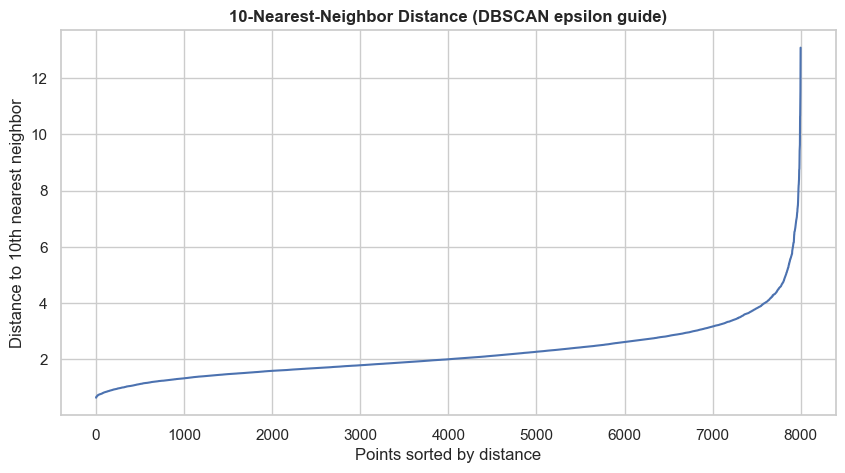

In [52]:
MIN_SAMPLES = 10

neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES, n_jobs=-1)
neighbors_fit = neighbors.fit(X_dbscan)
distances, _ = neighbors_fit.kneighbors(X_dbscan)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.title(f"{MIN_SAMPLES}-Nearest-Neighbor Distance (DBSCAN epsilon guide)")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {MIN_SAMPLES}th nearest neighbor")
plt.show()

###  Fit DBSCAN


In [53]:
EPSILON = 3.0  

dbscan = DBSCAN(
    eps=EPSILON,
    min_samples=MIN_SAMPLES,
    n_jobs=-1
)

dbscan_labels = dbscan.fit_predict(X_dbscan)

dbscan_results = X_all.loc[dbscan_indices].copy()
dbscan_results["DBSCAN_Cluster"] = dbscan_labels

n_noise = int((dbscan_labels == -1).sum())
n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
noise_pct = n_noise / len(dbscan_labels) * 100

print("DBSCAN clusters (excluding noise):", n_clusters_dbscan)
print("Noise / potential anomalies:", f"{n_noise:,}")
print("Noise percentage:", f"{noise_pct:.2f}%")

display(
    dbscan_results["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Number of records")
)

DBSCAN clusters (excluding noise): 1
Noise / potential anomalies: 689
Noise percentage: 8.61%


,Number of records
DBSCAN_Cluster,
-1,689
0,7311


### DBSCAN visualization 

,Number of Records,Percentage (%)
-1,689,8.61
0,7311,91.39


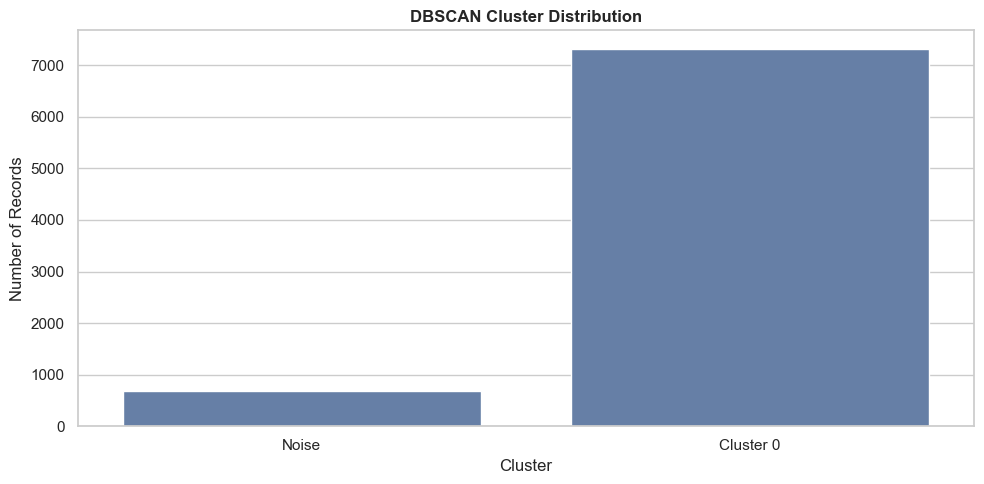

In [54]:
dbscan_counts = pd.Series(dbscan_labels).value_counts().sort_index()

dbscan_distribution = pd.DataFrame({
    "Number of Records": dbscan_counts,
    "Percentage (%)": dbscan_counts / len(dbscan_labels) * 100
})

display(dbscan_distribution.round(2))

cluster_labels = [
    "Noise" if cluster == -1 else f"Cluster {cluster}"
    for cluster in dbscan_distribution.index
]

plt.figure(figsize=(10, 5))

sns.barplot(
    x=cluster_labels,
    y=dbscan_distribution["Number of Records"].values,
    color="#5B7DB1"
)

plt.title("DBSCAN Cluster Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

### Compare DBSCAN noise with KMeans patterns

This comparison is descriptive only. DBSCAN noise points are unusual relative to the density structure in the sampled feature space; they are **potential anomalies**, not automatically errors or harmful pollution events.

In [55]:
# Attach KMeans labels to the DBSCAN sample for a cross-tabulation.
dbscan_comparison = dbscan_results[["DBSCAN_Cluster"]].copy()
dbscan_comparison["KMeans_Cluster"] = clustered_data.loc[
    dbscan_indices, "KMeans_Cluster"
].values

display(pd.crosstab(
    dbscan_comparison["KMeans_Cluster"],
    dbscan_comparison["DBSCAN_Cluster"],
    normalize="index"
).round(3))

noise_profile = X_dbscan.loc[dbscan_labels == -1].mean()
non_noise_profile = X_dbscan.loc[dbscan_labels != -1].mean()

if n_noise > 0 and n_noise < len(X_dbscan):
    comparison_profile = pd.DataFrame({
        "DBSCAN Noise": noise_profile,
        "DBSCAN Non-noise": non_noise_profile
    })
    display(comparison_profile.round(3))
else:
    print("Noise profile comparison skipped: DBSCAN did not produce both noise and non-noise points.")

DBSCAN_Cluster,-1,0
KMeans_Cluster,,
0,0.189,0.811
1,0.022,0.978


,DBSCAN Noise,DBSCAN Non-noise
O3_AQI_lag1,0.309,-0.003
O3_AQI_lag7,0.269,0.028
O3_AQI_lag30,0.212,0.020
O3_roll_mean7,0.299,0.019
O3_roll_std7,0.519,-0.035
NO2_AQI_lag1,0.631,-0.113
NO2_AQI_lag7,0.538,-0.101
NO2_AQI_lag30,0.513,-0.093
NO2_roll_mean7,0.673,-0.127
NO2_roll_std7,0.696,-0.115


## Save results for the project and Streamlit

In [56]:
from pathlib import Path

OUTPUT_DIR = Path("../reports/unsupervised")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save KMeans results
kmeans_output = clustered_data[
    ["data_split"] + pollution_features + ["KMeans_Cluster"]
]

kmeans_output.to_csv(
    OUTPUT_DIR / "kmeans_clustered_data.csv",
    index=False
)

cluster_distribution.to_csv(
    OUTPUT_DIR / "kmeans_cluster_distribution.csv"
)

cluster_profile.to_csv(
    OUTPUT_DIR / "kmeans_cluster_profile.csv"
)

pollutant_profile.to_csv(
    OUTPUT_DIR / "kmeans_pollutant_profile.csv"
)

# Save DBSCAN results
dbscan_results.to_csv(
    OUTPUT_DIR / "dbscan_sample_results.csv",
    index=False
)

# Save KMeans selection metrics
k_results.to_csv(
    OUTPUT_DIR / "kmeans_k_selection_metrics.csv",
    index=False
)

print("Unsupervised Learning results saved successfully:")
for file in OUTPUT_DIR.iterdir():
    print(f"- {file.name}")

Unsupervised Learning results saved successfully:
- dbscan_sample_results.csv
- kmeans_clustered_data.csv
- kmeans_cluster_distribution.csv
- kmeans_cluster_profile.csv
- kmeans_k_selection_metrics.csv
- kmeans_pollutant_profile.csv


In [57]:
import joblib

# Create folder for Streamlit artifacts
ARTIFACT_DIR = Path("../models/streamlit_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Save trained KMeans model
joblib.dump(
    kmeans,
    ARTIFACT_DIR / "kmeans_model.joblib"
)

# Save clustering configuration and feature names
kmeans_metadata = {
    "feature_names": pollution_features,
    "n_clusters": BEST_K,
    "random_state": RANDOM_STATE
}

joblib.dump(
    kmeans_metadata,
    ARTIFACT_DIR / "kmeans_metadata.joblib"
)

# Save DBSCAN configuration
dbscan_metadata = {
    "eps": EPSILON,
    "min_samples": MIN_SAMPLES,
    "sample_size": DBSCAN_SAMPLE_SIZE,
    "feature_names": pollution_features
}

joblib.dump(
    dbscan_metadata,
    ARTIFACT_DIR / "dbscan_metadata.joblib"
)

print("Unsupervised artifacts saved successfully!")

Unsupervised artifacts saved successfully!


## 12. Key Findings and Insights

### 1. KMeans Clustering Results

- The dataset was divided into **2 pollution-pattern clusters**.
- Cluster 0 contains **25,925 records (38.13%)**.
- Cluster 1 contains **42,066 records (61.87%)**.
- The two clusters show different historical pollutant patterns rather than identical pollution behavior.

### 2. Pollution Pattern Interpretation

Based on the scaled cluster profiles:

- **Cluster 0:** Shows relatively higher historical NO2, SO2, and CO values, while O3 values are below the overall feature reference mean.
- **Cluster 1:** Shows relatively higher O3 values, while NO2, SO2, and CO values are below their respective reference means.

This indicates two distinguishable historical pollution patterns in the dataset.

### 3. DBSCAN Findings

- DBSCAN identified noise points that were not part of dense regions in the selected feature space.
- Noise points were not equally distributed across KMeans clusters:
  - **18.9%** of Cluster 0 records were classified as noise.
  - **2.2%** of Cluster 1 records were classified as noise.
- Noise records showed higher average scaled values across the displayed pollutant-history features compared with non-noise records.

### 4. Main Project Insight

The results suggest that historical pollutant behavior can be grouped into distinct patterns, and DBSCAN can further identify records with unusual density characteristics.

These findings provide complementary insights: KMeans describes recurring pollution patterns, while DBSCAN highlights observations that differ from the dominant density structure.

### 5. Limitations

- Clusters represent similarities in historical pollutant features, not geographic regions.
- The features are scaled historical AQI variables, not direct current pollution measurements.
- DBSCAN was applied to a sample, so its findings should be interpreted within that sample.
- Noise points are potential anomalies and should not automatically be interpreted as pollution emergencies or measurement errors.